## Imports

In [7]:
import sys
sys.path.insert(0, "../modules")   # lets the notebook import our own modules

import pandas as pd
import matplotlib.pyplot as plt
from nve_api import fetch_reservoirs, fetch_areas, select_area, VALUE_COLS

## Areas covered by the API

In [8]:
# The API documents which areas exist: the country total, five elspot
# areas and the watercourse areas.
areas = fetch_areas()
areas

,navn,navn_langt,beskrivelse,omrType,omrnr
0,Norge,Norge,Hele landet,NO,0
1,NO 1,Elspotområde 1,Sørøst-Norge. Omfatter østlige del av Østlande...,EL,1
2,NO 2,Elspotområde 2,Sørvest-Norge. Omfatter mesteparten av Vestfol...,EL,2
3,NO 3,Elspotområde 3,Midt-Norge. Omfatter nordre og vestlige del av...,EL,3
4,NO 4,Elspotområde 4,Nord-Norge. Omfatter resten av Trøndelag og No...,EL,4
5,NO 5,Elspotområde 5,Vest-Norge. Omfatter midtre del av Vestland op...,EL,5
6,VASS1,Vassdragsområde 1,"Sørøst-Norge. Østlandet, Agder og deler av Rog...",VASS,1
7,VASS2,Vassdragsområde 2,Vest-Norge. Resten av Rogaland og Vestland.,VASS,2
8,VASS3,Vassdragsområde 3,"Midt-Norge. Møre og Romsdal, Trøndelag og sørl...",VASS,3
9,VASS4,Vassdragsområde 4,Nord-Norge. Resten av Nordland og nordover.,VASS,4


Beskrive...

## Downloading the data from the API

In [9]:
# Replaces pd.read_csv("reservoirs.csv") from Part 1
df_raw = fetch_reservoirs()
print("Rows:", len(df_raw))
print("From:", df_raw["date"].min(), "to:", df_raw["date"].max())
df_raw.head()

Rows: 14913
From: 1995-01-08 00:00:00 to: 2026-10-04 00:00:00


,date,area_type,area_number,iso_year,iso_week,filling_level,capacity_TWh,stored_energy_TWh,next_publication_date,filling_level_prev_week,filling_level_change
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


## Selecting Norway total

In [10]:
# Every week appears once per area and the rows are unsorted,
# so filter to one area and sort before plotting.
df = select_area(df_raw, area_type="NO", area_number=0)
df.describe()

,filling_level,capacity_TWh,stored_energy_TWh,filling_level_prev_week,filling_level_change
count,1657.000000,1657.00000,1657.000000,1657.000000,1657.000000
mean,0.622128,87.43758,54.397365,0.622172,-0.000044
std,0.195744,0.00000,17.115341,0.195764,0.027681
min,0.180250,87.43758,15.760602,0.180260,-0.144643
25%,0.460930,87.43758,40.302580,0.460930,-0.022025
50%,0.647463,87.43758,56.612630,0.647445,-0.005528
75%,0.789030,87.43758,68.990850,0.789030,0.016337
max,0.966610,87.43758,84.518060,0.966610,0.125774


## Plotting each column seperately (the same as in Part 1)

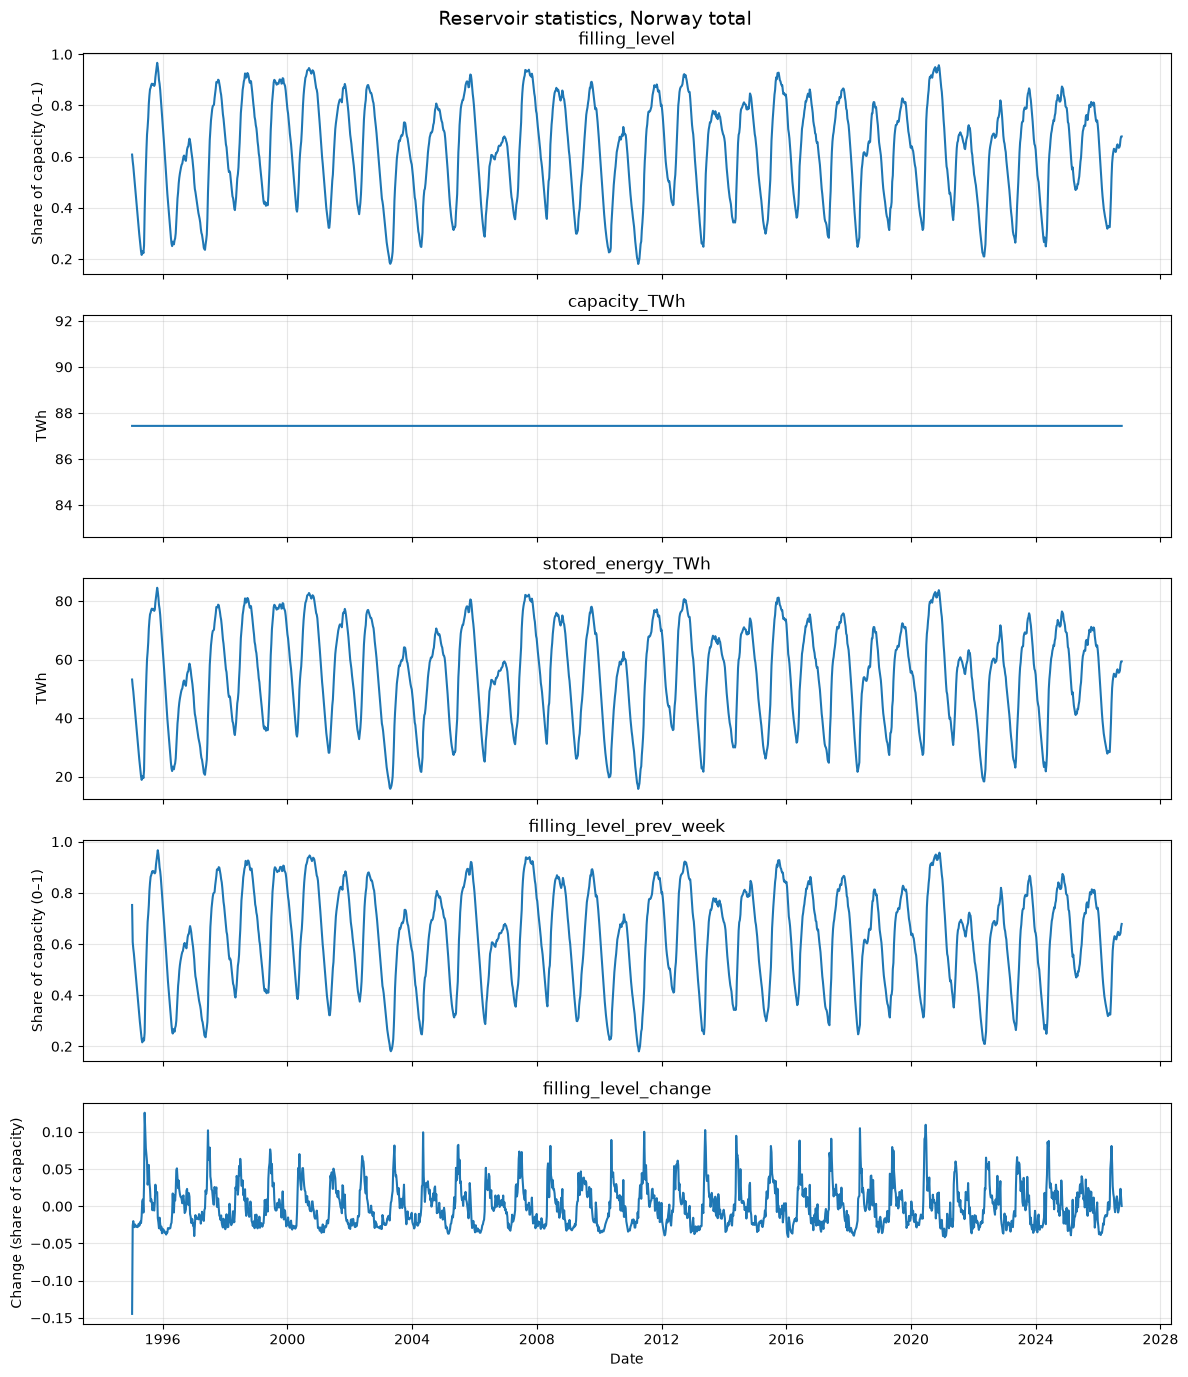

In [13]:
# Unit for each column, used as y-axis labels
units = {
    "filling_level": "Share of capacity (0–1)",
    "capacity_TWh": "TWh",
    "stored_energy_TWh": "TWh",
    "filling_level_prev_week": "Share of capacity (0–1)",
    "filling_level_change": "Change (share of capacity)",
}

# One subplot per column, sharing the time axis
fig, axes = plt.subplots(len(VALUE_COLS), 1, figsize=(12, 14), sharex=True)
for ax, col in zip(axes, VALUE_COLS):
    ax.plot(df.index, df[col])
    ax.set_title(col)
    ax.set_ylabel(units[col])
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("Date")
fig.suptitle("Reservoir statistics, Norway total", fontsize=14)
plt.tight_layout()
plt.show()

## All columns plotted together (the same as in part 1)

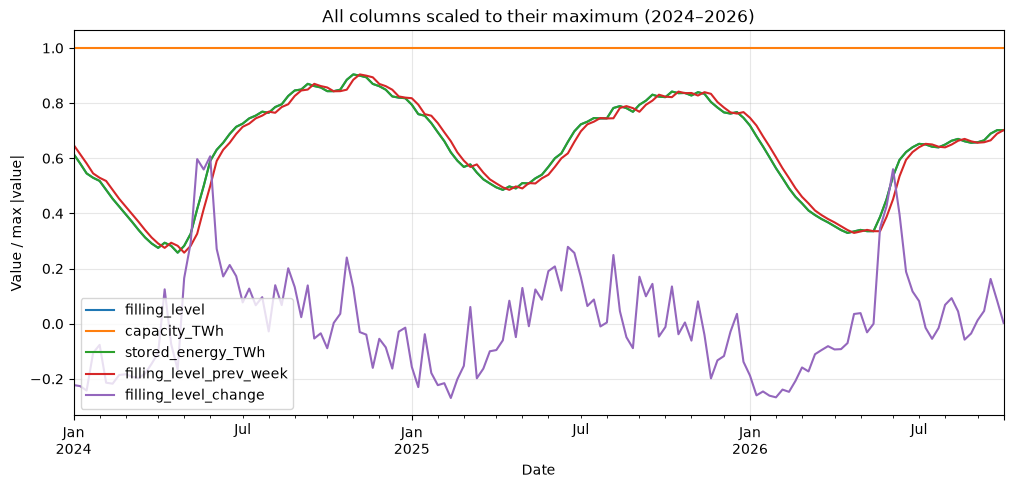

In [14]:
# Scaling each column by its largest absolute value -> all values inside [-1, 1]
df_scaled = df / df.abs().max()

# Plotting only the last 3 years so the lines are more readable
df_scaled.loc["2024":].plot(figsize=(12, 5))
plt.title("All columns scaled to their maximum (2024–2026)")
plt.xlabel("Date")
plt.ylabel("Value / max |value|")
plt.grid(alpha=0.3)
plt.legend(loc="lower left")
plt.show()

I used the same code as in part 1 to recreate the plots that I have been created by the data from the API, instead of the CSV file. This workd because df has the same shape as before. 

In [6]:
import sys
sys.path.insert(0, "../modules")   # from App/notebooks/ up to App/modules/
from spark_env import get_spark

spark = get_spark()
spark

JAVA_HOME   : C:\Program Files\Eclipse Adoptium\jdk-17.0.20.101-hotspot
HADOOP_HOME : C:\hadoop
Java        : openjdk version "17.0.20.1" 2026-08-18


## LOG AND AI USAGE